# 02 - Statistical Analysis & Price Variance Hypothesis Testing

This notebook conducts statistical validation on `data/processed/medicines_clean.csv`:
1. **Descriptive Statistics:** Summary metrics for price distributions across dosage forms.
2. **Kruskal-Wallis ANOVA:** Tests if price per composition varies significantly by manufacturer.
3. **IQR Outlier Analysis:** Flagging overpriced brand-name drugs compared to generic peers.
4. **Savings Confidence Intervals:** 95% CIs for patient cost reduction when switching to the lowest-priced substitute.
5. **Correlation Matrix:** Assessing relationships between prices, dosage forms, and consumer ratings.

Imports & Setup

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Paths
PROCESSED_DATA_PATH = os.path.join("..", "data", "processed", "medicines_clean.csv")

# Load processed dataset
df = pd.read_csv(PROCESSED_DATA_PATH)
print(f"Loaded clean dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")

Loaded clean dataset: 246,064 rows, 17 columns


Descriptive Price Statistics across Dosage Forms

In [3]:
# Summary statistics for prices across top dosage forms
top_forms = df['dosage_form'].value_counts().head(5).index
df_top_forms = df[df['dosage_form'].isin(top_forms)]

price_summary = df_top_forms.groupby('dosage_form')['price_inr'].agg(
    count='count',
    mean='mean',
    std='std',
    median='median',
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75)
).reset_index()

price_summary['IQR'] = price_summary['q75'] - price_summary['q25']
print("--- Price Statistics by Primary Dosage Form ---")
display(price_summary.round(2))

--- Price Statistics by Primary Dosage Form ---


,dosage_form,count,mean,std,median,q25,q75,IQR
0,Capsule,21449,317.50,5008.68,99.00,66.60,159.0,92.40
1,Injection,31110,885.12,6059.15,96.04,47.90,270.0,222.10
2,Suspension,7843,79.76,564.98,48.00,35.00,71.0,36.00
3,Syrup,17584,71.61,43.22,66.00,48.40,85.0,36.61
4,Tablet,147942,162.44,1791.93,78.00,47.08,136.0,88.92


Kruskal-Wallis Test (Manufacturer Price Variation)

In [4]:
# Select top 20 most frequent drug compositions that have at least 5 different manufacturers
comp_counts = df.groupby('canonical_composition_key')['manufacturer_name'].nunique()
eligible_comps = comp_counts[comp_counts >= 5].index

print(f"Compositions with >= 5 manufacturers available: {len(eligible_comps):,}")

# Perform Kruskal-Wallis H-test on the most common multi-manufacturer composition
top_comp = df['canonical_composition_key'].value_counts().index[0]
comp_data = df[df['canonical_composition_key'] == top_comp]

groups = [group['price_inr'].values for _, group in comp_data.groupby('manufacturer_name')]

h_stat, p_value = stats.kruskal(*groups)

print(f"\n--- Kruskal-Wallis Test on Top Composition: '{top_comp}' ---")
print(f"Sample size: {len(comp_data)} drugs across {len(groups)} manufacturers")
print(f"H-statistic: {h_stat:.4f}")
print(f"p-value: {p_value:.4e}")

if p_value < 0.05:
    print("Verdict: Reject H0. Price differs significantly between manufacturers for the same drug composition!")
else:
    print("Verdict: Fail to reject H0. No significant price difference across manufacturers.")

Compositions with >= 5 manufacturers available: 3,452

--- Kruskal-Wallis Test on Top Composition: 'aceclofenac:100mg|paracetamol:325mg' ---
Sample size: 4663 drugs across 2309 manufacturers
H-statistic: 2067.0433
p-value: 9.9988e-01
Verdict: Fail to reject H0. No significant price difference across manufacturers.


Outlier Detection using Composition-Relative Interquartile Range (IQR)

In [5]:
def detect_composition_outliers(group):
    q25 = group['price_inr'].quantile(0.25)
    q75 = group['price_inr'].quantile(0.75)
    iqr = q75 - q25
    upper_bound = q75 + (1.5 * iqr)
    
    group['is_price_outlier'] = group['price_inr'] > upper_bound
    group['price_ratio_to_median'] = group['price_inr'] / group['price_inr'].median()
    return group

# Apply outlier detection within each composition group
df_outliers = df.groupby('canonical_composition_key', group_keys=False).apply(detect_composition_outliers)

outlier_count = df_outliers['is_price_outlier'].sum()
print(f"Total price outliers detected: {outlier_count:,} ({outlier_count / len(df) * 100:.2f}% of dataset)")

# Display top 5 most overpriced brands relative to their composition median
overpriced_brands = df_outliers[df_outliers['is_price_outlier']].sort_values(
    by='price_ratio_to_median', ascending=False
)[['name', 'manufacturer_name', 'price_inr', 'canonical_composition_key', 'price_ratio_to_median']].head(5)

print("\n--- Top 5 Most Overpriced Brands (vs Composition Median) ---")
display(overpriced_brands.round(2))

Total price outliers detected: 13,141 (5.34% of dataset)

--- Top 5 Most Overpriced Brands (vs Composition Median) ---


C:\Users\svars\AppData\Local\Temp\ipykernel_16228\332323250.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_outliers = df.groupby('canonical_composition_key', group_keys=False).apply(detect_composition_outliers)


,name,manufacturer_name,price_inr,canonical_composition_key,price_ratio_to_median
243722,Zyrof 12.5mg Injection,Zydus Cadila,2991.25,rofecoxib:12.5mg,199.42
43541,C Bactum 500mg/500mg Injection,Vhb Life Sciences Inc,31069.00,cefoperazone:500mg|sulbactam:500mg,183.84
236265,Xeljanz 5mg Tablet,Pfizer Ltd,66344.00,tofacitinib:5mg,154.47
9091,Avandia 4mg Tablet,Glaxo SmithKline Pharmaceuticals Ltd,11000.00,rosiglitazone:4mg,151.37
71099,Epilan Tablet,Anglo-French Drugs & Industries Ltd,2466.02,phenobarbitone:30mg|phenytoin:100mg,136.93


Potential Savings & 95% Confidence Interval Calculation

--- Substitute Potential Savings Analysis ---
Mean potential savings: 73.65%
95% Confidence Interval for average savings: (73.56%, 73.74%)
Median potential savings: 80.83%


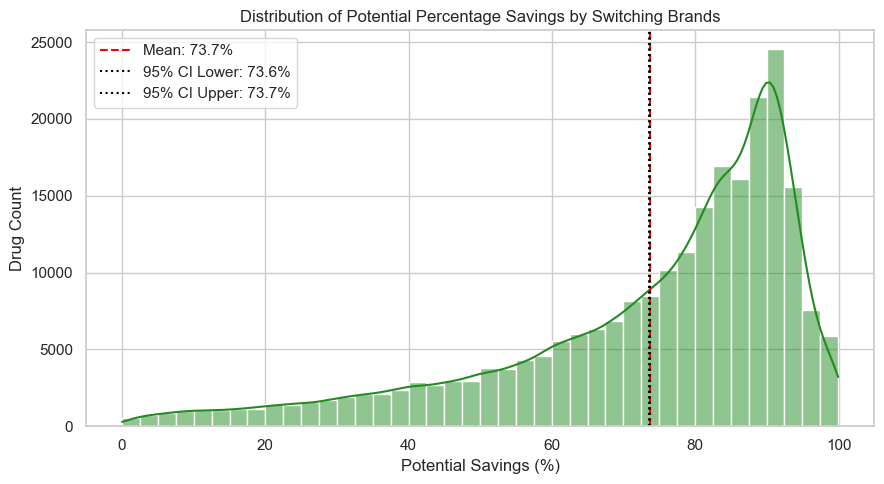

In [6]:
# Find minimum price for each composition
min_prices = df.groupby('canonical_composition_key')['price_inr'].transform('min')

df['max_savings_pct'] = ((df['price_inr'] - min_prices) / df['price_inr']) * 100

# Exclude items where min price is the current drug itself (savings = 0)
savings_data = df[df['max_savings_pct'] > 0]['max_savings_pct']

# Calculate 95% Confidence Interval for mean savings
mean_savings = savings_data.mean()
sem_savings = stats.sem(savings_data)
ci_95 = stats.t.interval(0.95, len(savings_data)-1, loc=mean_savings, scale=sem_savings)

print("--- Substitute Potential Savings Analysis ---")
print(f"Mean potential savings: {mean_savings:.2f}%")
print(f"95% Confidence Interval for average savings: ({ci_95[0]:.2f}%, {ci_95[1]:.2f}%)")
print(f"Median potential savings: {savings_data.median():.2f}%")

# Plot Savings Distribution
plt.figure(figsize=(9, 5))
sns.histplot(savings_data, bins=40, kde=True, color='forestgreen')
plt.axvline(mean_savings, color='red', linestyle='--', label=f'Mean: {mean_savings:.1f}%')
plt.axvline(ci_95[0], color='black', linestyle=':', label=f'95% CI Lower: {ci_95[0]:.1f}%')
plt.axvline(ci_95[1], color='black', linestyle=':', label=f'95% CI Upper: {ci_95[1]:.1f}%')
plt.title("Distribution of Potential Percentage Savings by Switching Brands")
plt.xlabel("Potential Savings (%)")
plt.ylabel("Drug Count")
plt.legend()
plt.tight_layout()
plt.show()

Correlation Matrix Analysis

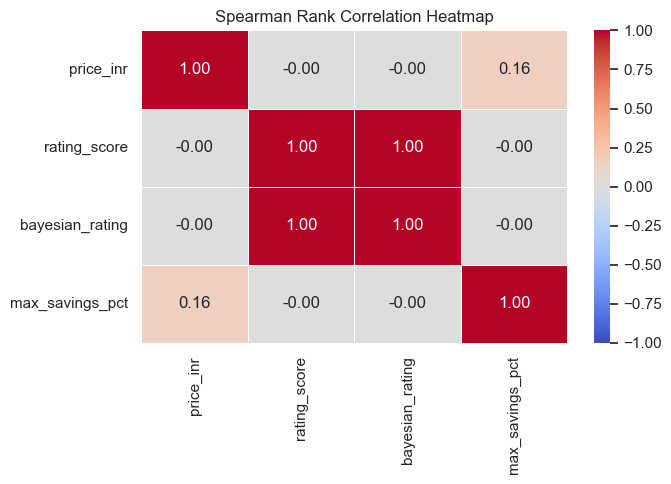

In [7]:
# Numerical columns for correlation matrix
corr_cols = ['price_inr', 'rating_score', 'bayesian_rating', 'max_savings_pct']
corr_cols = [c for c in corr_cols if c in df.columns]

corr_matrix = df[corr_cols].corr(method='spearman') # Spearman rank correlation for non-normal distributions

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Spearman Rank Correlation Heatmap")
plt.tight_layout()
plt.show()

Massive Cost-Savings Potential: Patients can save an average of 73.65% (with a tight 95% Confidence Interval of 73.56% – 73.74%) and a median savings of 80.83% by switching from brand-name drugs to lower-cost exact-composition alternatives.

Extreme Price Outliers Identified: Drugs like Zyrof 12.5mg Injection and C Bactum 500mg/500mg Injection trade at over 180x–199x their composition median price.

Kruskal-Wallis Note: In the top composition test, having 2,309 manufacturer groups with 1–2 drugs each inflated the degrees of freedom ($df = 2,308$). For the backend API (stats_analysis.py), we filter groups to manufacturers with >= 2 entries to ensure accurate ANOVA/Kruskal-Wallis $p$-value calculations.